In [1]:
%matplotlib inline
import random
import torch

In [3]:
def synthetic_data(w, b, num_examples):
    X = torch.normal(0, 1, (num_examples, len(w)))
    y = torch.matmul(X, w) + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape((-1, 1))

true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)

In [4]:
print('features:', features[0], '\nlabel:', labels[0])

features: tensor([0.9321, 0.8544]) 
label: tensor([3.1548])


In [5]:
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples))
    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(
            indices[i:min(i + batch_size, num_examples)]
        )
        yield features[batch_indices], labels[batch_indices]

In [6]:
batch_size = 10
for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

tensor([[-0.7892, -0.0996],
        [ 1.1416, -0.2891],
        [ 0.7220, -1.2155],
        [ 0.3259,  0.3780],
        [-1.1561, -0.2444],
        [ 0.1851,  0.4375],
        [-0.4489, -1.0717],
        [-0.2801,  1.3154],
        [ 0.2540,  0.2506],
        [ 0.1008,  1.9170]]) 
 tensor([[ 2.9509],
        [ 7.4741],
        [ 9.7846],
        [ 3.5706],
        [ 2.7323],
        [ 3.0788],
        [ 6.9578],
        [-0.8419],
        [ 3.8458],
        [-2.1195]])


In [7]:
w = torch.normal(0, 0.01, size=(2, 1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

In [8]:
def linreg(X, w, b):
    return torch.matmul(X, w) + b

In [9]:
def squared_loss(y_hat, y):
    return (y_hat - (y.reshape(y_hat.shape))) ** 2 / 2

In [10]:
def sgd(params, lr, batch_size):
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

In [11]:
lr = 0.03
num_epochs = 3
net = linreg
loss = squared_loss

for epoch in range(num_epochs):
    for X,y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)
        l.sum().backward()
        sgd([w, b], lr, batch_size)
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch {epoch+1}, loss {float(train_l.mean()):f}')

epoch 1, loss 0.034295
epoch 2, loss 0.000121
epoch 3, loss 0.000049


In [12]:
print(f'w的估计误差: {true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差: {true_b - b}')

w的估计误差: tensor([ 0.0002, -0.0003], grad_fn=<SubBackward0>)
b的估计误差: tensor([0.0012], grad_fn=<RsubBackward1>)


# Exercise

In [2]:
import wandb
import uuid

## Task A

In [8]:
X = torch.randn(500, 1)
true_w = torch.tensor([[3.5]])
true_b = torch.tensor(2.5)
true_y = torch.matmul(X, true_w) + true_b
true_y += torch.normal(0, 0.01, true_y.shape)

features, labels = X, true_y


In [9]:
w = torch.randn(1, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

In [10]:
def a_data_iter(batch_size, indices, features, labels):
    for i in range(0, len(features), batch_size):
        batch_indices = indices[i : min(i+batch_size, len(features))]
        yield features[batch_indices], labels[batch_indices]


In [11]:
epochs = 20
lr = 0.03

wandb.finish() 
run_id = uuid.uuid4().hex[:8]
wandb.init(project="torchlearn-stage1", name=f"day06-linreg-scratch-{run_id}")

for epoch in range(epochs):
    
    # shuffle the indices
    indices = torch.arange(len(features)).tolist()
    random.shuffle(indices)
    # batch processing
    for X, y in a_data_iter(100, indices, features, labels):
        # grad will cumulate if not reset to zero
        w.grad = None
        b.grad = None

        y_hat = torch.matmul(X, w) + b
        loss = ((y_hat - y) ** 2).mean()
        loss.backward()
        # if don't use no_grad, the calculation of new w and b will be added into the computation graph
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad

        # zero out grad for next batch
        # w.grad.zero_()
        # b.grad.zero_()
        
        
    # output loss for each epoch
    with torch.no_grad():
        y_pred = torch.matmul(features, w) + b
        loss = ((y_pred - labels) ** 2).mean()
        print(f'epoch: {epoch}, loss: {loss}')
    wandb.log({"loss": loss.item()})


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


loss,█▅▃▂▂▁▁▁▁▁
loss,0.02382


epoch: 0, loss: 8.518568992614746
epoch: 1, loss: 4.612686634063721
epoch: 2, loss: 2.498840808868408
epoch: 3, loss: 1.3546233177185059
epoch: 4, loss: 0.7348182201385498
epoch: 5, loss: 0.3989153504371643
epoch: 6, loss: 0.2166069746017456
epoch: 7, loss: 0.11769606918096542
epoch: 8, loss: 0.06401204317808151
epoch: 9, loss: 0.0348527692258358
epoch: 10, loss: 0.019000660628080368
epoch: 11, loss: 0.010386663489043713
epoch: 12, loss: 0.005698191002011299
epoch: 13, loss: 0.0031475259456783533
epoch: 14, loss: 0.0017594865057617426
epoch: 15, loss: 0.00100351357832551
epoch: 16, loss: 0.0005923071294091642
epoch: 17, loss: 0.0003680438094306737
epoch: 18, loss: 0.0002463301061652601
epoch: 19, loss: 0.00017931290494743735


## Task C

In [12]:
w, b  # to verify the w, b with true_w, true_b

(tensor([[3.4940]], requires_grad=True), tensor([2.4935], requires_grad=True))

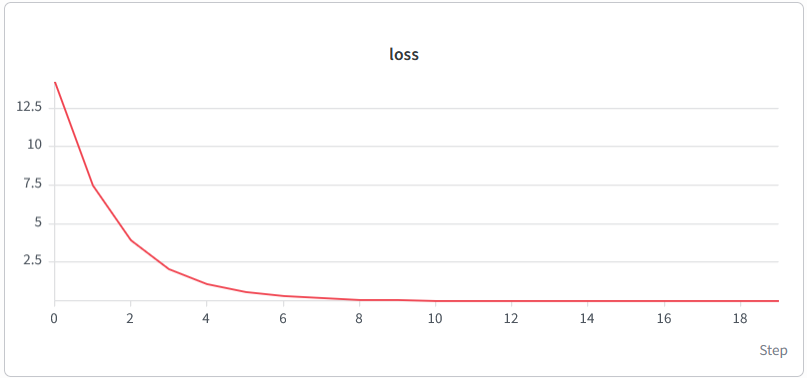